# Lab 6 — Localization: model vs real robot
Trajectory **r028**, TRIK robot. Odometry was logged in the simulator and on the real robot (wheel radius r = 0.0375 m, wheel base B = 0.194 m on the real robot).

Log format: `x,y,time` — x, y in m, time in ms, no header.

- `odometry_data_sim.txt` — simulator
- `odometry_data_real.txt` — final real-robot run (v3: turns controlled by heading)
- `odometry_data_real_v1.txt`, `odometry_data_real_v2.txt` — earlier real runs (time-based turns, then heading-controlled turns), kept for comparison

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import files
    uploaded = files.upload()   # select the txt files
except ImportError:
    pass  # running locally: files must be in the current folder

In [2]:
def load(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip().replace(';', ',').rstrip(',')
            if not line:
                continue
            try:
                rows.append([float(v) for v in line.split(',')[:3]])
            except ValueError:
                continue  # skip header / broken lines
    a = np.array(rows)
    return a[:, 0], a[:, 1], a[:, 2]

x_s, y_s, t_s = load('odometry_data_sim.txt')
x_r, y_r, t_r = load('odometry_data_real.txt')
print(f'sim : {len(x_s)} samples')
print(f'real: {len(x_r)} samples')

sim : 4387 samples
real: 386 samples


## 1. Trajectories on one plot

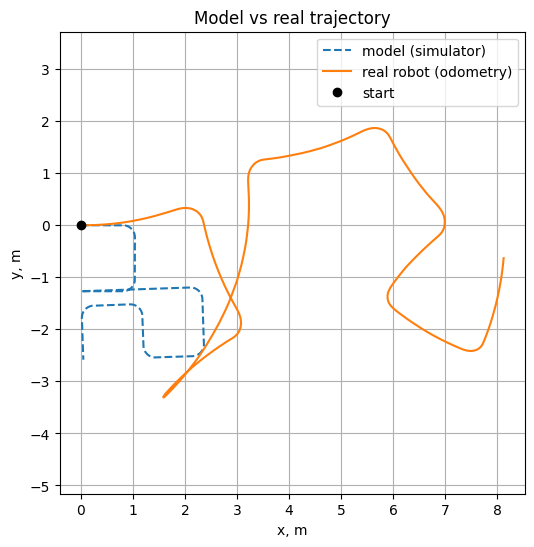

In [3]:
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

## 2. Position error over time
Simulator resampled onto the real-robot timestamps.

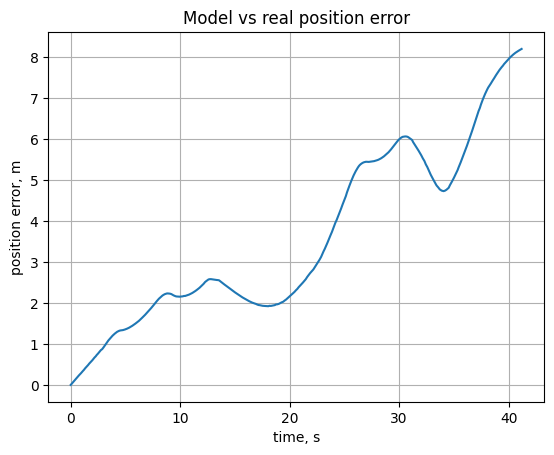

Final odometry error (sim vs real): 8.19 m
Max error: 8.19 m
Mean error: 3.56 m


In [4]:
t_s0, t_r0 = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r0, t_s0, x_s)
ys_i = np.interp(t_r0, t_s0, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r0 / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.2f} m')
print(f'Max error: {err.max():.2f} m')
print(f'Mean error: {err.mean():.2f} m')

## 3. All real runs vs the model
v1: turns by time. v2: turns by heading. v3 (final): heading-controlled turns, tighter arcs, spin overshoot corrected.

run                     path, m   end x   end y  final err  mean err
sim                       10.69    0.05   -2.58          -         -


v1 (time turns)           18.55   -2.37   -6.61       4.70      3.85
v2 (heading turns)        25.20    4.90    2.36       6.93      3.53
v3 (final)                22.25    8.12   -0.63       8.19      3.56


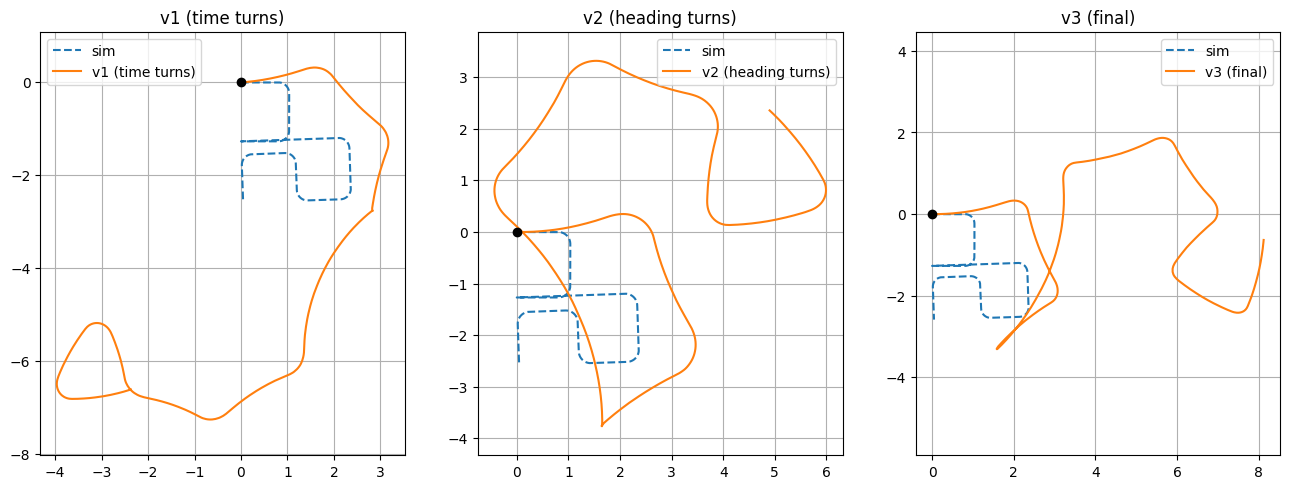

In [5]:
runs = {
    'v1 (time turns)':       'odometry_data_real_v1.txt',
    'v2 (heading turns)':    'odometry_data_real_v2.txt',
    'v3 (final)':            'odometry_data_real.txt',
}
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
print(f"{'run':22s} {'path, m':>8s} {'end x':>7s} {'end y':>7s} {'final err':>10s} {'mean err':>9s}")
d = np.hypot(np.diff(x_s), np.diff(y_s))
print(f"{'sim':22s} {d.sum():8.2f} {x_s[-1]:7.2f} {y_s[-1]:7.2f} {'-':>10s} {'-':>9s}")
for a, (name, path) in zip(ax, runs.items()):
    x, y, t = load(path)
    e = np.hypot(x - np.interp(t - t[0], t_s0, x_s), y - np.interp(t - t[0], t_s0, y_s))
    d = np.hypot(np.diff(x), np.diff(y))
    print(f'{name:22s} {d.sum():8.2f} {x[-1]:7.2f} {y[-1]:7.2f} {e[-1]:10.2f} {e.mean():9.2f}')
    a.plot(x_s, y_s, '--', label='sim'); a.plot(x, y, label=name); a.plot(0, 0, 'ko')
    a.axis('equal'); a.grid(True); a.legend(); a.set_title(name)
plt.show()

## 4. Turn angles on the real robot (final run)
Heading change in each turn, found from the direction of the odometry path.

In [6]:
dx, dy = np.diff(x_r), np.diff(y_r)
d = np.hypot(dx, dy)
dt = np.diff(t_r) / 1000
tm = (t_r[1:] - t_r[0]) / 1000
th = np.unwrap(np.arctan2(dy, dx))
rate = np.degrees(np.diff(th)) / dt[1:]
rs = np.convolve(rate, np.ones(5) / 5, 'same')
on = np.abs(rs) > 25

print(f"{'start, s':>9s} {'end, s':>7s} {'turn, deg':>10s} {'path, m':>8s}")
i = 0
while i < len(on):
    if on[i]:
        j = i
        while j < len(on) and on[j]:
            j += 1
        a0, b0 = max(i - 2, 0), min(j + 2, len(th) - 1)
        print(f'{tm[i]:9.1f} {tm[j]:7.1f} {np.degrees(th[b0] - th[a0]):10.1f} {d[i:j].sum():8.2f}')
        i = j
    else:
        i += 1

 start, s  end, s  turn, deg  path, m
      3.4     4.8      -94.3     0.64
      8.0     9.3      -86.8     0.61
     12.0    13.1      180.3     0.30
     20.9    22.3      -84.9     0.61
     25.7    27.1      -87.4     0.63
     29.8    31.3      -90.9     0.70
     33.4    34.8       91.8     0.69
     37.2    38.5       93.3     0.63


## 5. Measured end point
After the real run, measure the robot's actual final position with a tape (same axes as the odometry, start = origin) and enter it below.

In [7]:
x_meas, y_meas = None, None   # <-- fill in, metres, e.g. x_meas, y_meas = 1.20, 0.45

print(f'Last line of real log (odometry belief): x = {x_r[-1]:.3f} m, y = {y_r[-1]:.3f} m')
if x_meas is not None:
    e = np.hypot(x_r[-1] - x_meas, y_r[-1] - y_meas)
    print(f'Measured end point:                    x = {x_meas:.3f} m, y = {y_meas:.3f} m')
    print(f'Odometry vs tape measurement error: {e:.3f} m')

    plt.figure(figsize=(6, 6))
    plt.plot(x_s, y_s, '--', label='model (simulator)')
    plt.plot(x_r, y_r, label='real robot (odometry)')
    plt.plot(x_r[-1], y_r[-1], 'rs', label='odometry end')
    plt.plot(x_meas, y_meas, 'g*', ms=14, label='measured end')
    plt.axis('equal'); plt.grid(True); plt.legend()
    plt.xlabel('x, m'); plt.ylabel('y, m'); plt.title('End point: odometry vs tape')
    plt.show()

Last line of real log (odometry belief): x = 8.122 m, y = -0.633 m


## 6. Conclusion (draft — edit after measuring the end point)
The real trajectory diverges from the model from the very first segment: the real robot drives about twice as fast as the simulator at the same motor power (about 0.57 m/s vs 0.27 m/s), so every straight step is about 1.1 m instead of 0.8 m, and the path grows to about 22 m against 10.7 m. The two real wheels are not equal, so the heading also drifts by 10–20° on steps that should be straight, and since heading error dominates position error, this bends every later segment. After switching the turns to heading control, the turns themselves are close to 90° and 180°, but the errors from the straight steps still accumulate, so the final odometry error against the model is about 8 m. The robot does not know it is wrong: odometry only integrates its own encoders, so the logged path looks smooth and consistent even though the real position is different. Only an outside measurement, like the tape-measured end point, shows the true error.